## Газовая динамика — компактная версия
Полностью консервативная схема: $u_t=-p_s$, $x_t=u$, $V_t=u_s$, $E_t=-pu_s$, $p=(\gamma-1)E/V$.
Те же данные, что в `laba2.ipynb`; прогонка встроена в Ньютон, своих функций нет.

In [1]:
%matplotlib inline
import numpy as np; import matplotlib.pyplot as plt
from pathlib import Path
out = Path('results/compressed'); out.mkdir(parents=True, exist_ok=True)
L, T, N, M, gamma = 1., 0.12, 200, 80, 1.4; h = L/N; tau = T/M; mu = tau**2/(4*h**2)
s = np.linspace(0,L,N+1); sc = (s[:-1]+s[1:])/2; t = np.linspace(0,T,M+1)
X = np.zeros((M+1,N+1)); U = np.zeros_like(X); V = np.zeros((M+1,N)); E = np.zeros_like(V); P = np.zeros_like(V)
X[0] = s; V[0] = 1.; P[0] = 1.+0.1*np.exp(-((sc-0.5)/0.12)**2); E[0] = P[0]*V[0]/(gamma-1)

### Ньютон и прогонка
Временные средние берутся с весом 1/2. Граничные скорости равны нулю.

In [2]:
iterations = []; n = N-1
for j in range(M):
    v = U[j].copy()
    for k in range(20):
        dV = tau/(2*h)*(np.diff(v)+np.diff(U[j])); V1 = V[j]+dV
        D = V[j]+(gamma+1)*dV/2; B = (gamma-1)*(E[j]-P[j]*dV/2)
        if min(V1.min(),D.min(),B.min()) <= 0: raise RuntimeError(f'Нефизическое состояние: слой {j}')
        p1 = B/D; dp = -((gamma-1)*P[j]+(gamma+1)*p1)/(2*D)
        F = v[1:-1]-U[j,1:-1]+tau/(2*h)*np.diff(p1+P[j])
        if max(abs(F)) < 1e-12: break
        a = mu*dp[1:-1]; b = 1.-mu*(dp[:-1]+dp[1:]); rhs = -F
        alpha = np.zeros(n-1); beta = np.zeros(n); alpha[0] = a[0]/b[0]; beta[0] = rhs[0]/b[0]
        for i in range(1,n):
            z = b[i]-a[i-1]*alpha[i-1]
            if i < n-1: alpha[i] = a[i]/z
            beta[i] = (rhs[i]-a[i-1]*beta[i-1])/z
        du = np.zeros(n); du[-1] = beta[-1]
        for i in range(n-2,-1,-1): du[i] = beta[i]-alpha[i]*du[i+1]
        v[1:-1] += du
    else: raise RuntimeError(f'Нет сходимости Ньютона: слой {j}')
    iterations.append(k+1); U[j+1] = v; X[j+1] = X[j]+tau*(U[j]+v)/2
    V[j+1] = V1; P[j+1] = p1; E[j+1] = E[j]-(P[j]+p1)*dV/2

### Проверка и графики
$H=h\sum_i[E_i+(u_i^2+u_{i+1}^2)/4]$ — полная энергия при неподвижных стенках.

Ошибка энергии: 5.551115123125783e-15 ; объёма и сетки: 2.3359092438113294e-13
min ρ: 0.9503657331882646 ; min p: 1.0000000034306396 ; итерации Ньютона: 2 3


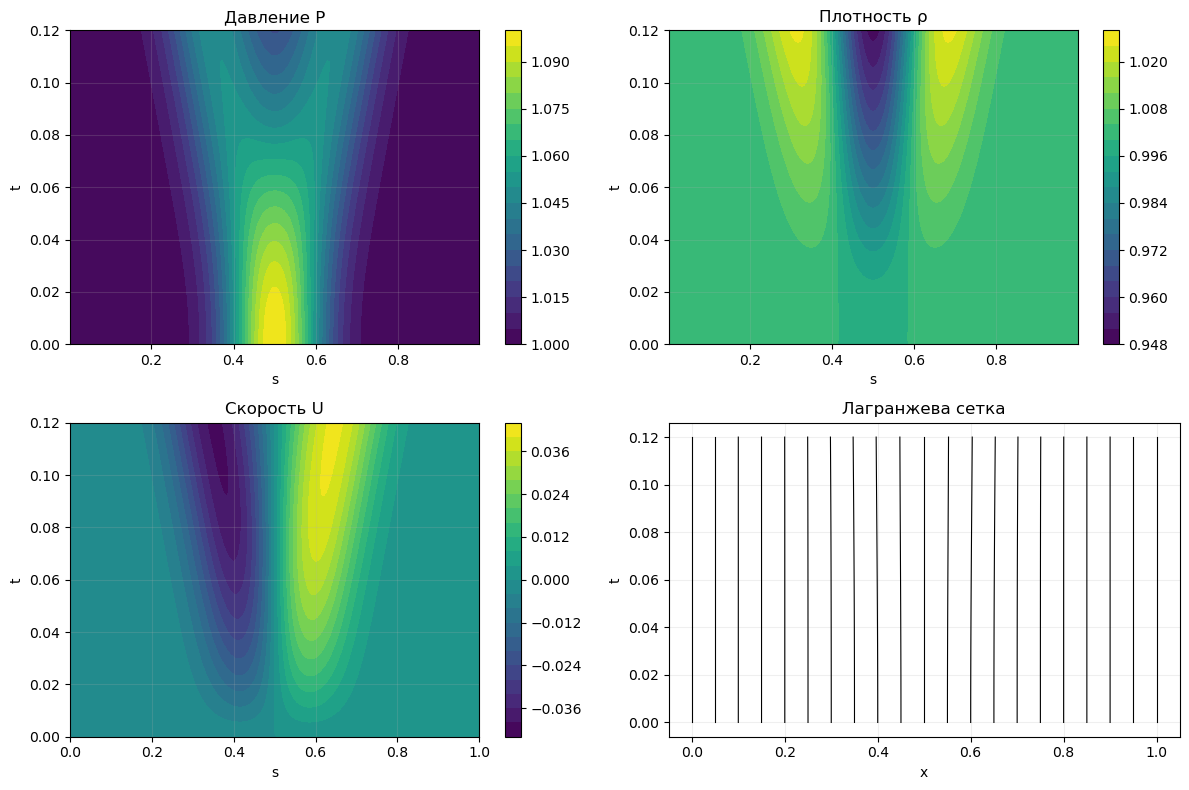

In [3]:
rho = 1/V; H = h*np.sum(E+(U[:,:-1]**2+U[:,1:]**2)/4,axis=1); err = abs(H/H[0]-1)
geometry_error = np.max(abs(V-np.diff(X,axis=1)/h))
print('Ошибка энергии:',err.max(), '; объёма и сетки:',geometry_error)
print('min ρ:',rho.min(), '; min p:',P.min(), '; итерации Ньютона:',min(iterations),max(iterations))
assert err.max() < 1e-10 and geometry_error < 1e-10 and rho.min() > 0 and P.min() > 0
np.savez(out/'gas.npz',X=X,U=U,V=V,E=E,P=P,s=s,t=t,energy=H,energy_error=err)
fig, ax = plt.subplots(2,2,figsize=(12,8))
for a, field, grid, title in [(ax[0,0],P,sc,'Давление P'),(ax[0,1],rho,sc,'Плотность ρ'),(ax[1,0],U,s,'Скорость U')]:
    im = a.contourf(grid,t,field,levels=20); fig.colorbar(im,ax=a); a.set(title=title,xlabel='s',ylabel='t')
for i in range(0,N+1,10): ax[1,1].plot(X[:,i],t,lw=0.8,color='black')
ax[1,1].set(title='Лагранжева сетка',xlabel='x',ylabel='t')
for a in ax.flat: a.grid(alpha=0.2)
plt.tight_layout(); plt.savefig(out/'gas.png',dpi=150); plt.show()

### Анимация без функции обновления

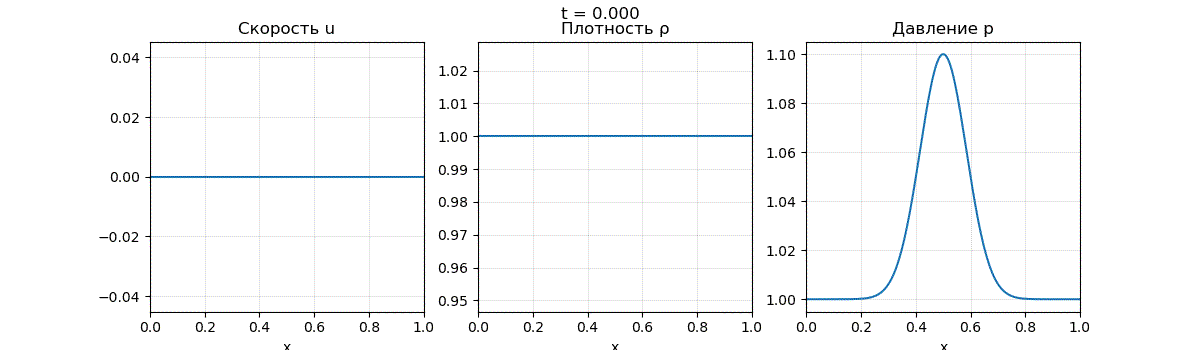

In [4]:
from PIL import Image as PILImage
from IPython.display import Image, display
fig, ax = plt.subplots(1,3,figsize=(12,3.5)); fields = [U,rho,P]; lines = []; frames = []
for a, field, title in zip(ax,fields,['Скорость u','Плотность ρ','Давление p']):
    line, = a.plot([],[]); lines.append(line); d = max(0.05*np.ptp(field),1e-6)
    a.set(xlim=(0,L),ylim=(field.min()-d,field.max()+d),title=title,xlabel='x'); a.grid(alpha=0.3)
label = fig.suptitle('')
for j in range(0,M+1,2):
    xc = (X[j,:-1]+X[j,1:])/2
    for line, xx, field in zip(lines,[X[j],xc,xc],fields): line.set_data(xx,field[j])
    label.set_text(f't = {t[j]:.3f}'); fig.canvas.draw()
    frames.append(PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())[:,:,:3].copy()))
frames[0].save(out/'gas.gif',save_all=True,append_images=frames[1:],duration=67,loop=0)
plt.close(fig); display(Image(filename=str(out/'gas.gif')))
for frame in frames: frame.close()

### Вывод
Импульс распадается на две волны; энергия сохраняется с точностью решения Ньютона.
Рассмотрен гладкий пример. Результаты этой версии — в `results/compressed/`.